# DSA5205 Project 2 | Ridge L2 — Final Detailed Experiment

**Primary label:** `target_forward_return` (decimal holding-period return, **not** SPY-relative). **Frequency:** monthly / quarterly / semiannual. **Design:** Train 2010–2020 → forward Validation 2021–2022 → refit with labels available by 2022-12-31 → fixed-model OOS Test 2023–2025.

This notebook uses the **FINAL pipeline** modules and their model/portfolio contract; it does **not** generate synthetic data or silently substitute missing stock observations. It produces detailed prediction diagnostics, portfolio comparison vs Momentum / EW30 / SPY / QQQ, trade-level weight changes, monthly stock P&L contributions, and cost sensitivity. It does not claim FIFO tax-lot realized P&L or executable live fills.

**Important:** The upstream dataset is based on *today's* S&P 500 constituents traced backward, so survivorship / membership look-ahead bias remains. Test period has previously been inspected; additional changes must be disclosed as exploratory.

## 0. Configuration and project discovery

In [1]:
from pathlib import Path
import os, sys, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Can be overridden via DSA5205_PROJECT_ROOT environment variable.
project_env = os.environ.get('DSA5205_PROJECT_ROOT')
if project_env:
    ROOT = Path(project_env).expanduser().resolve()
else:
    # If macOS denies os.getcwd(), set the environment variable above and restart.
    try:
        here = Path.cwd()
    except PermissionError as exc:
        raise RuntimeError('Cannot access current directory. Set DSA5205_PROJECT_ROOT to the extracted FINAL project folder, then restart kernel.') from exc
    ROOT = next((q for q in [here, *here.parents] if (q/'src'/'pipeline.py').is_file() and (q/'src'/'models.py').is_file()), None)
if ROOT is None or not (ROOT/'src'/'models.py').is_file():
    raise FileNotFoundError('Open the notebook inside DSA5205_Project2_FINAL or set DSA5205_PROJECT_ROOT.')
sys.path.insert(0,str(ROOT))
from src.pipeline import FEATURES
from src.models import GRIDS, build_model, run_model
from src.backtest import portfolio_backtest, performance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import spearmanr

FREQUENCY = 'monthly'   # 'quarterly' or 'semiannual'
COST_BPS = 20
SEED = 42
OUT = ROOT/'outputs'/'ridge_detailed'/FREQUENCY
OUT.mkdir(parents=True,exist_ok=True)
np.random.seed(SEED)
print('ROOT:',ROOT,'\nFREQUENCY:',FREQUENCY,'\nTARGET: target_forward_return')

ROOT: /Users/hc/Desktop/NUS DSML/DSA 5205/Project2/DSA-5205/DSA5205_Project2_Pipeline 
FREQUENCY: monthly 
TARGET: target_forward_return


## 1. Load and audit model-ready data

In [2]:
path = ROOT/'data'/'processed_ready'/FREQUENCY/'model_ready.parquet'
if not path.is_file():
    raise FileNotFoundError(f'{path} missing. Run: python run_pipeline.py --frequency all')
df = pd.read_parquet(path).copy()
for c in ['decision_date','execution_date','label_end_date']:
    df[c] = pd.to_datetime(df[c])
TARGET='target_forward_return'
required=FEATURES+[TARGET,'ticker','split','decision_date','execution_date','label_end_date','mom_2_12','spy_return','qqq_return']
missing=set(required)-set(df.columns)
if missing: raise KeyError(f'Missing required columns: {sorted(missing)}')
if df.empty or df.ticker.astype(str).str.startswith('SYN').any():
    raise RuntimeError('Empty or synthetic input; real data required')
if df.duplicated(['decision_date','ticker']).any(): raise ValueError('Duplicate decision-date/ticker')
if not np.isfinite(df[FEATURES+[TARGET,'spy_return','qqq_return']].to_numpy(dtype=float)).all():
    raise ValueError('NaN/Inf in model-ready numeric fields')
if not ((df.decision_date<df.execution_date)&(df.execution_date<df.label_end_date)).all():
    raise ValueError('Decision / execution / label-end ordering invalid')
counts=df.groupby('decision_date').ticker.nunique()
print('Rows:',len(df),'Tickers:',df.ticker.nunique(),'Decision periods:',len(counts))
print('Period sizes:',counts.value_counts().sort_index().to_dict())
print(df.groupby('split').agg(rows=('ticker','size'),dates=('decision_date','nunique'),start=('decision_date','min'),end=('decision_date','max')).to_string())
display(df[FEATURES+[TARGET]].describe(percentiles=[.01,.05,.5,.95,.99]).T)


Rows: 5760 Tickers: 448 Decision periods: 192
Period sizes: {30: 192}
            rows  dates      start        end
split                                        
test        1080     36 2023-01-31 2025-12-31
train       3960    132 2010-01-29 2020-12-31
validation   720     24 2021-01-29 2022-12-30


,count,mean,std,min,1%,5%,50%,95%,99%,max
mom_21,5760.0,0.019448,0.107173,-0.637909,-0.231520,-0.124302,0.014961,0.173508,0.337288,2.138439
mom_63,5760.0,0.057840,0.209710,-0.797049,-0.397477,-0.214295,0.046152,0.343822,0.741867,2.821509
mom_126,5760.0,0.128206,0.387460,-0.899168,-0.543014,-0.312201,0.083944,0.675429,1.549843,7.038929
mom_2_12,5760.0,0.324047,0.823495,-0.933108,-0.687566,-0.457789,0.149300,1.558541,3.868644,11.667147
relative_mom_63,5760.0,0.022234,0.197247,-0.760380,-0.369192,-0.226857,0.009060,0.299571,0.659642,2.739947
vol_21,5760.0,0.303142,0.205906,0.047195,0.093959,0.120199,0.246750,0.674044,1.162713,2.527916
vol_63,5760.0,0.314423,0.197407,0.075242,0.118235,0.142801,0.254057,0.686620,1.101680,2.131531
beta_252,5760.0,1.046050,0.491522,-0.251889,0.083418,0.359364,1.000247,1.950077,2.628932,4.455382
drawdown_63,5760.0,-0.080774,0.091188,-0.801951,-0.442982,-0.259289,-0.053181,0.000000,0.000000,0.000000
ma_ratio_50,5760.0,0.016455,0.086532,-0.626827,-0.213206,-0.107685,0.016984,0.140544,0.261071,0.932884


**Audit interpretation:** A 30-row monthly decision date is necessary for an apples-to-apples Top-10 backtest. The upstream pipeline may have discarded dates with incomplete labels; these dates must be documented, not treated as realized zero-return trades.

## 2. Temporal integrity and eligible fitting samples

In [3]:
TRAIN_CUTOFF=pd.Timestamp('2020-12-31')
VAL_CUTOFF=pd.Timestamp('2022-12-31')
TEST_START=pd.Timestamp('2023-01-01')
train=df[(df.split=='train')&(df.label_end_date<=TRAIN_CUTOFF)].copy()
val=df[(df.split=='validation')&(df.label_end_date<=VAL_CUTOFF)].copy()
test=df[df.split=='test'].copy()
assert len(train) and len(val) and len(test)
assert (train.decision_date < pd.Timestamp('2021-01-01')).all()
assert val.decision_date.between(pd.Timestamp('2021-01-01'),pd.Timestamp('2022-12-31')).all()
assert test.decision_date.between(pd.Timestamp('2023-01-01'),pd.Timestamp('2025-12-31')).all()
assert (test.groupby('decision_date').ticker.nunique()==30).all(), 'Test period has incomplete labeled candidate dates'
refit=df[(df.decision_date<TEST_START)&(df.label_end_date<=VAL_CUTOFF)].copy()
print('Train rows:',len(train),'Validation rows:',len(val),'Final refit rows:',len(refit),'Test rows:',len(test))
print('Train last realized label:',train.label_end_date.max(),'Final refit last label:',refit.label_end_date.max())


Train rows: 3900 Validation rows: 660 Final refit rows: 4620 Test rows: 1080
Train last realized label: 2020-12-01 00:00:00 Final refit last label: 2022-12-01 00:00:00


## 3. Ridge regularization grid: training vs validation losses

,alpha,train_mse,train_mae,train_r2,validation_mse,validation_mae,validation_r2
0,0.100000,0.009668,0.066376,0.049994,0.012195,0.081308,-0.071852
1,1.000000,0.009668,0.066375,0.049994,0.012195,0.081307,-0.071845
2,10.000000,0.009668,0.066371,0.049981,0.012194,0.081299,-0.071769
3,100.000000,0.009675,0.066371,0.049299,0.012184,0.081228,-0.070895
4,1000.000000,0.009740,0.066475,0.042863,0.012081,0.080753,-0.061827
5,10000.000000,0.009902,0.066674,0.027016,0.011743,0.079991,-0.032191


Selected alpha: 10000.0 (minimum validation MSE; tie -> smaller alpha)


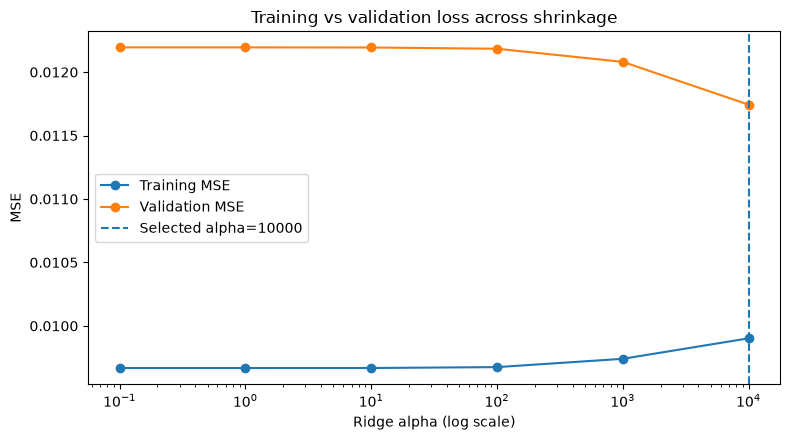

In [4]:
grid=[]
for params in GRIDS['ridge']:
    m=build_model('ridge',params,SEED)
    m.fit(train[FEATURES],train[TARGET])
    row={'alpha':params['alpha']}
    for label,part in [('train',train),('validation',val)]:
        pred=m.predict(part[FEATURES]); y=part[TARGET]
        row.update({f'{label}_mse':mean_squared_error(y,pred),f'{label}_mae':mean_absolute_error(y,pred),f'{label}_r2':r2_score(y,pred)})
    grid.append(row)
tuning=pd.DataFrame(grid).sort_values('alpha')
best_alpha=float(tuning.sort_values(['validation_mse','alpha']).iloc[0].alpha)
tuning.to_csv(OUT/'ridge_train_validation_grid.csv',index=False)
display(tuning.style.format(precision=6))
print('Selected alpha:',best_alpha,'(minimum validation MSE; tie -> smaller alpha)')
fig,ax=plt.subplots(figsize=(8,4.5))
ax.semilogx(tuning.alpha,tuning.train_mse,marker='o',label='Training MSE')
ax.semilogx(tuning.alpha,tuning.validation_mse,marker='o',label='Validation MSE')
ax.axvline(best_alpha,linestyle='--',label=f'Selected alpha={best_alpha:g}')
ax.set(xlabel='Ridge alpha (log scale)',ylabel='MSE',title='Training vs validation loss across shrinkage')
ax.legend();fig.tight_layout();fig.savefig(OUT/'alpha_mse.png',dpi=170);plt.show()


Ridge is solved by penalized least squares, **not** iterative epochs. The alpha–loss plot is the correct complexity/validation diagnostic. If the best alpha is at the grid boundary, report this as a limitation; do not expand the grid based on the already-inspected test set.

## 4. Final refit, coefficients and OOS predictions

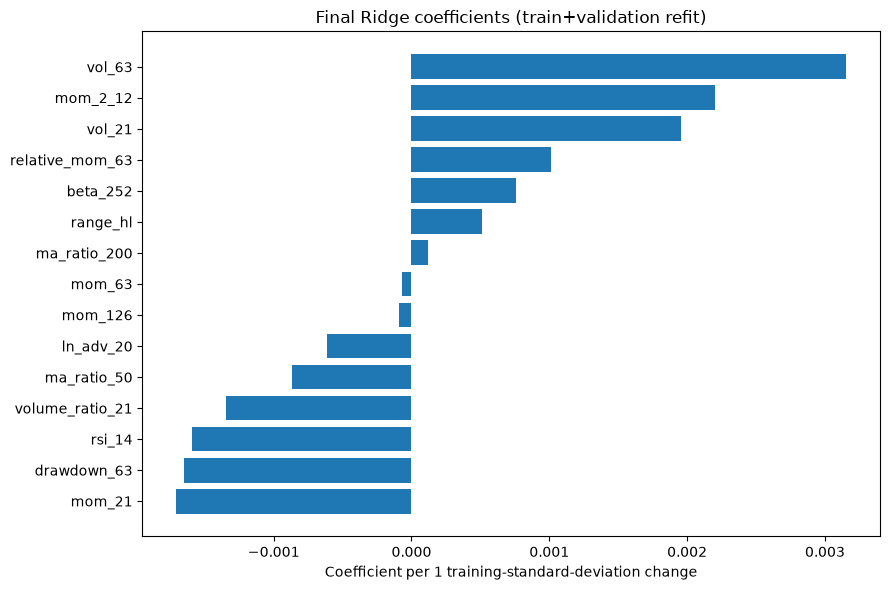

Refit training rows: 4620 OOS predictions: 1080


In [5]:
final=build_model('ridge',{'alpha':best_alpha},SEED)
final.fit(refit[FEATURES],refit[TARGET])
test=test.copy()
test['prediction']=final.predict(test[FEATURES])
test['model']='ridge'
test=test.sort_values(['decision_date','prediction','ticker'],ascending=[True,False,True])
test['pred_rank']=test.groupby('decision_date').cumcount()+1
coefs=pd.DataFrame({'feature':FEATURES,'standardized_coefficient':final.named_steps['model'].coef_}).sort_values('standardized_coefficient')
coefs.to_csv(OUT/'ridge_coefficients.csv',index=False)
fig,ax=plt.subplots(figsize=(9,6));ax.barh(coefs.feature,coefs.standardized_coefficient)
ax.set(xlabel='Coefficient per 1 training-standard-deviation change',title='Final Ridge coefficients (train+validation refit)')
fig.tight_layout();fig.savefig(OUT/'ridge_coefficients.png',dpi=170);plt.show()
test.to_parquet(OUT/'test_predictions.parquet',index=False)
test.to_csv(OUT/'test_predictions.csv',index=False)
print('Refit training rows:',len(refit),'OOS predictions:',len(test))


## 5. Prediction diagnostics: MSE, MAE, OOS R², rank IC and baseline

{
  "test_mse": 0.014751635718049026,
  "test_mae": 0.07816726685796917,
  "test_r2_standard": 0.027640254128523778,
  "test_oos_r2_vs_trainval_mean": 0.030895213201485472,
  "baseline_test_mse": 0.015221920187580314,
  "best_alpha": 10000.0,
  "mean_monthly_rank_ic": 0.09557533061426277,
  "positive_ic_fraction": 0.5833333333333334
}


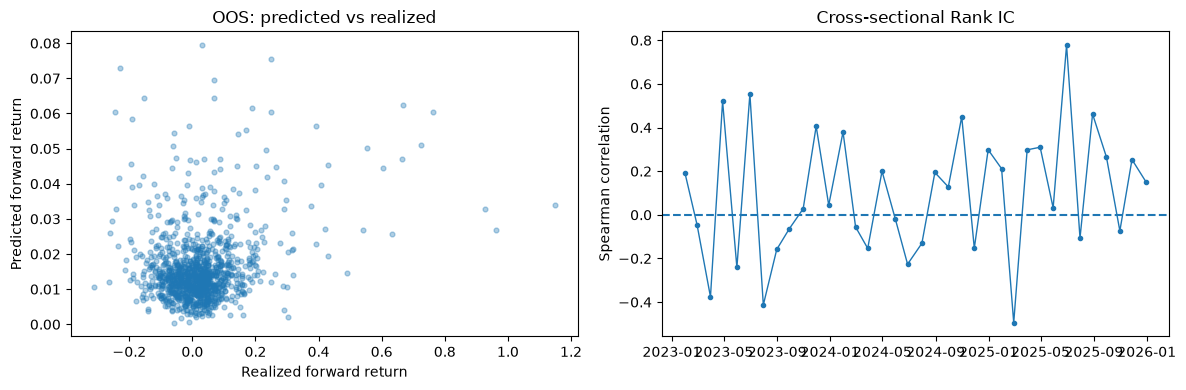

In [6]:
# Historical mean baseline fitted ONLY on available pre-test labels.
baseline_mean=float(refit[TARGET].mean())
y=test[TARGET].to_numpy(); pred=test.prediction.to_numpy()
base=np.full(len(y),baseline_mean)
oos_r2_vs_mean=1-np.sum((y-pred)**2)/np.sum((y-base)**2)
pred_metrics={'test_mse':float(mean_squared_error(y,pred)),'test_mae':float(mean_absolute_error(y,pred)),
              'test_r2_standard':float(r2_score(y,pred)),'test_oos_r2_vs_trainval_mean':float(oos_r2_vs_mean),
              'baseline_test_mse':float(mean_squared_error(y,base)),'best_alpha':best_alpha}
ics=[]
for date,g in test.groupby('decision_date'):
    ic=float(spearmanr(g.prediction,g[TARGET]).statistic) if g.prediction.nunique()>1 and g[TARGET].nunique()>1 else np.nan
    ics.append({'decision_date':date,'rank_ic':ic,'stocks':len(g)})
ic_df=pd.DataFrame(ics)
pred_metrics['mean_monthly_rank_ic']=float(ic_df.rank_ic.mean())
pred_metrics['positive_ic_fraction']=float((ic_df.rank_ic>0).mean())
(OUT/'prediction_metrics.json').write_text(json.dumps(pred_metrics,indent=2))
ic_df.to_csv(OUT/'monthly_rank_ic.csv',index=False)
print(json.dumps(pred_metrics,indent=2))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(y,pred,s=12,alpha=.35)
axes[0].set(xlabel='Realized forward return',ylabel='Predicted forward return',title='OOS: predicted vs realized')
axes[1].plot(ic_df.decision_date,ic_df.rank_ic,marker='.',linewidth=1)
axes[1].axhline(0,linestyle='--');axes[1].set(title='Cross-sectional Rank IC',ylabel='Spearman correlation')
fig.tight_layout();fig.savefig(OUT/'prediction_diagnostics.png',dpi=170);plt.show()


## 6. Unified portfolio backtest: Ridge / Momentum / EW30 / SPY / QQQ

,strategy,periods,annualized_return,annualized_volatility,sharpe_rf0,max_drawdown,mean_two_way_turnover
3,model_top10,36,0.714753,0.298121,1.988531,-0.159443,1.297960
4,momentum_top10,36,0.708459,0.288017,2.031368,-0.114550,0.959591
0,QQQ,36,0.287672,0.149224,1.784010,-0.090031,0.027778
2,equal_weight_30,36,0.251187,0.172171,1.395802,-0.127402,1.287329
1,SPY,36,0.208899,0.114139,1.730447,-0.078005,0.027778


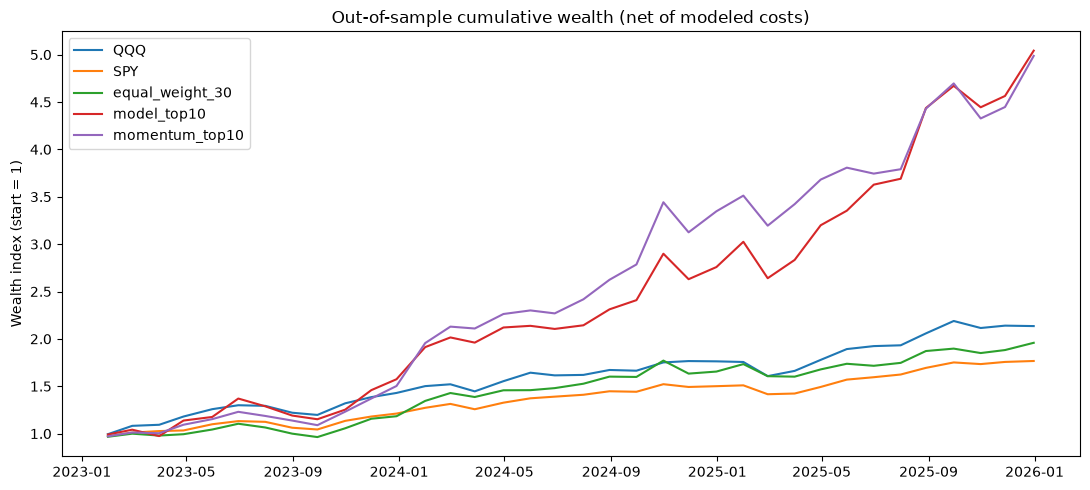

In [7]:
# Reuse the same cost and drift accounting used by other project models.
returns,trades,holdings=portfolio_backtest(test,frequency=FREQUENCY,cost_bps=COST_BPS,top_n=10)
summary=performance(returns,frequency=FREQUENCY)
display(summary.sort_values('annualized_return',ascending=False))
returns.to_csv(OUT/'portfolio_period_returns.csv',index=False)
trades.to_csv(OUT/'rebalance_trade_log.csv',index=False)
holdings.to_csv(OUT/'monthly_stock_pnl.csv',index=False)
summary.to_csv(OUT/'portfolio_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(11,5))
for strategy,g in returns.groupby('strategy'):
    g=g.sort_values('decision_date')
    ax.plot(g.decision_date,(1+g.net_return).cumprod(),label=strategy)
ax.set(title='Out-of-sample cumulative wealth (net of modeled costs)',ylabel='Wealth index (start = 1)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'cumulative_net_wealth.png',dpi=170);plt.show()


**Important backtest convention:** The existing shared backtest uses weight-level accounting and fractional shares. It computes each period's marked-to-market return, even for positions that continue into the next period. The `monthly_stock_pnl.csv` file is **period contribution**, not FIFO realized trade P&L. The trade log records delta target weights, not actual share quantities or dollar tax lots. Fees are approximated as `cost_bps/10000 × sum(abs(delta_weight))`. The ETFs have a single entry fee and are thereafter treated as buy-and-hold.

## 7. Detailed rebalance actions, winners / losers, holdings and overlap

In [8]:
ridge_trades=trades[trades.strategy=='model_top10'].copy()
ridge_hold=holdings[holdings.strategy=='model_top10'].copy()
# Associate each period's stock return with the current decision's holdings.
ridge_hold['period_profit_loss']=np.where(ridge_hold.period_stock_return>0,'PROFIT',np.where(ridge_hold.period_stock_return<0,'LOSS','FLAT'))
ridge_hold['gross_contribution_pct_points']=100*ridge_hold.gross_return_contribution
ridge_hold['period_stock_return_pct']=100*ridge_hold.period_stock_return
ridge_hold.to_csv(OUT/'ridge_stock_by_period_profit_loss.csv',index=False)
ridge_trades.to_csv(OUT/'ridge_rebalance_actions.csv',index=False)
print('Recent stock-period P&L:');display(ridge_hold.tail(20))
print('Recent trades (including exits):');display(ridge_trades.tail(25))
print('Trade action counts:');display(ridge_trades.action.value_counts().to_frame('count'))
# Names selected by both models on each date
rows=[]
for date,g in test.groupby('decision_date'):
    r=set(g.nlargest(10,'prediction').ticker)
    m=set(g.nlargest(10,'mom_2_12').ticker)
    rows.append({'decision_date':date,'ridge_vs_momentum_overlap':len(r&m),'ridge_names':', '.join(sorted(r)),'momentum_names':', '.join(sorted(m))})
overlap=pd.DataFrame(rows)
overlap.to_csv(OUT/'ridge_momentum_monthly_overlap.csv',index=False)
display(overlap.tail(8))


Recent stock-period P&L:


,strategy,decision_date,ticker,target_weight,period_stock_return,gross_return_contribution,profit_status,period_profit_loss,gross_contribution_pct_points,period_stock_return_pct
340,model_top10,2025-11-28,BE,0.1,-0.154184,-0.015418,LOSS,LOSS,-1.541838,-15.418381
341,model_top10,2025-11-28,HOOD,0.1,-0.064577,-0.006458,LOSS,LOSS,-0.645768,-6.457675
342,model_top10,2025-11-28,FISV,0.1,0.099121,0.009912,PROFIT,PROFIT,0.991211,9.912110
343,model_top10,2025-11-28,PLTR,0.1,0.098788,0.009879,PROFIT,PROFIT,0.987879,9.878790
344,model_top10,2025-11-28,DDOG,0.1,-0.137281,-0.013728,LOSS,LOSS,-1.372808,-13.728076
345,model_top10,2025-11-28,KLAC,0.1,0.081296,0.008130,PROFIT,PROFIT,0.812962,8.129617
346,model_top10,2025-11-28,CMG,0.1,0.088863,0.008886,PROFIT,PROFIT,0.888629,8.886293
347,model_top10,2025-11-28,GLW,0.1,0.066707,0.006671,PROFIT,PROFIT,0.667067,6.670667
348,model_top10,2025-11-28,TPR,0.1,0.195453,0.019545,PROFIT,PROFIT,1.954531,19.545309
349,model_top10,2025-11-28,TEL,0.1,0.024182,0.002418,PROFIT,PROFIT,0.241819,2.418194


Recent trades (including exits):


,strategy,decision_date,ticker,pretrade_weight,target_weight,delta_weight,action,cost_contribution
557,model_top10,2025-11-28,IBKR,0.095137,0.0,-0.095137,EXIT,0.000190
558,model_top10,2025-11-28,ICE,0.112809,0.0,-0.112809,EXIT,0.000226
559,model_top10,2025-11-28,KEY,0.109907,0.0,-0.109907,EXIT,0.000220
560,model_top10,2025-11-28,KLAC,0.000000,0.1,0.100000,BUY,0.000200
561,model_top10,2025-11-28,MRNA,0.098725,0.0,-0.098725,EXIT,0.000197
562,model_top10,2025-11-28,PLTR,0.084391,0.1,0.015609,ADD,0.000031
563,model_top10,2025-11-28,TEL,0.000000,0.1,0.100000,BUY,0.000200
564,model_top10,2025-11-28,TPR,0.000000,0.1,0.100000,BUY,0.000200
565,model_top10,2025-12-31,APH,0.000000,0.1,0.100000,BUY,0.000200
566,model_top10,2025-12-31,BE,0.082131,0.1,0.017869,ADD,0.000036


Trade action counts:


,count
action,
BUY,232
EXIT,222
ADD,76
REDUCE,52


,decision_date,ridge_vs_momentum_overlap,ridge_names,momentum_names
28,2025-05-30,3,"APP, CVNA, FSLR, MRNA, NKE, OXY, PLTR, SMCI, T...","APP, CVNA, GILD, IBM, NFLX, PLTR, PM, T, VRSN,..."
29,2025-06-30,3,"APP, BA, HOOD, LYB, OXY, PLTR, REGN, SMCI, STZ...","APP, CAH, GE, GILD, HOOD, IBM, JCI, NFLX, PLTR..."
30,2025-07-31,6,"APP, DOW, HOOD, HWM, JBL, MRNA, NFLX, PLTR, SL...","APP, BKNG, CAH, HOOD, HWM, IBKR, JBL, NFLX, PL..."
31,2025-08-29,6,"APP, CNC, DASH, DOW, HOOD, HWM, IBKR, MU, PLTR...","APH, APP, C, DASH, GE, HOOD, HWM, IBKR, PLTR, RCL"
32,2025-09-30,5,"AMP, BE, CCL, DOW, HOOD, LUV, MRNA, PLTR, RCL,...","BE, C, CCL, DASH, GS, HOOD, HWM, LYV, PLTR, RCL"
33,2025-10-31,5,"BE, CNC, DOW, GEV, HOOD, IBKR, ICE, KEY, MRNA,...","APH, BE, C, GE, GEV, GLW, HOOD, HWM, IBKR, PLTR"
34,2025-11-28,7,"BE, CMG, DDOG, FISV, GLW, HOOD, KLAC, PLTR, TE...","APH, BE, GE, GLW, HOOD, HWM, KLAC, PLTR, TEL, TPR"
35,2025-12-31,7,"APH, BE, FISV, HCA, IDXX, KLAC, LITE, QCOM, SM...","APH, BE, CVS, GE, HCA, HWM, IDXX, KLAC, LITE, WDC"


## 8. Cost sensitivity: re-run the same holdings under alternative costs

In [9]:
cost_rows=[]
for bps in [0,5,10,20,40]:
    ret,_,_=portfolio_backtest(test,frequency=FREQUENCY,cost_bps=bps,top_n=10)
    perf=performance(ret,frequency=FREQUENCY)
    perf['cost_bps_per_side']=bps
    cost_rows.append(perf)
cost_sensitivity=pd.concat(cost_rows,ignore_index=True)
cost_sensitivity.to_csv(OUT/'transaction_cost_sensitivity.csv',index=False)
display(cost_sensitivity.pivot(index='cost_bps_per_side',columns='strategy',values='annualized_return'))


strategy,QQQ,SPY,equal_weight_30,model_top10,momentum_top10
cost_bps_per_side,,,,,
0,0.288534,0.209726,0.289684,0.766606,0.746499
5,0.288319,0.209520,0.279959,0.753510,0.736917
10,0.288103,0.209313,0.270302,0.740503,0.727383
20,0.287672,0.208899,0.251187,0.714753,0.708459
40,0.286807,0.208071,0.213746,0.664293,0.671175


## 9. OOS performance by calendar year and risk charts

strategy,QQQ,SPY,equal_weight_30,model_top10,momentum_top10
year,,,,,
2023,0.429425,0.211686,0.183706,0.574264,0.502902
2024,0.233366,0.238620,0.398251,0.751960,1.226813
2025,0.211050,0.177178,0.183417,0.828111,0.490044


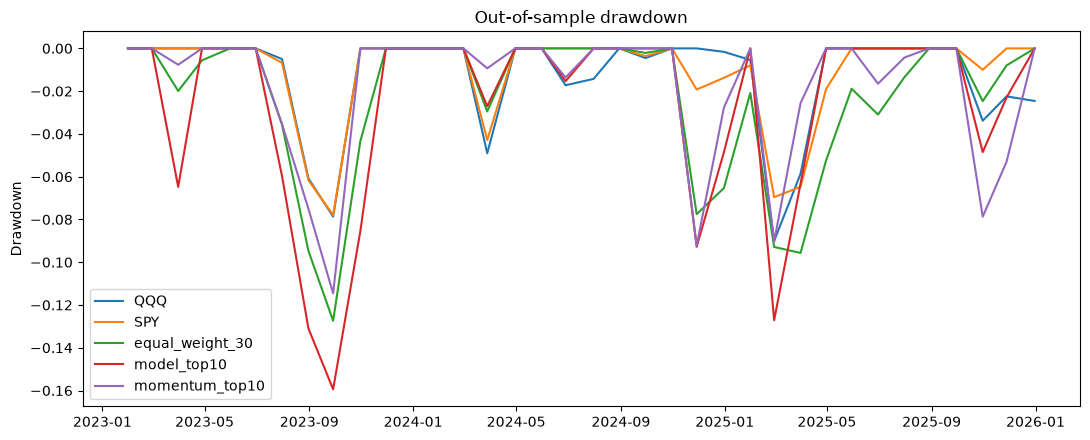

In [10]:
r=returns.copy();r['year']=pd.to_datetime(r.decision_date).dt.year
annual_factor={'monthly':12,'quarterly':4,'semiannual':2}[FREQUENCY]
period_rows=[]
for (strategy,year),g in r.groupby(['strategy','year']):
    rr=g.sort_values('decision_date').net_return.to_numpy(dtype=float)
    period_rows.append({'strategy':strategy,'year':year,'periods':len(rr),
                        'compounded_return':float(np.prod(1+rr)-1),
                        'annualized_sharpe_rf0':float(np.mean(rr)/np.std(rr,ddof=1)*np.sqrt(annual_factor)) if len(rr)>1 and np.std(rr,ddof=1)>0 else np.nan})
yearly=pd.DataFrame(period_rows)
yearly.to_csv(OUT/'yearly_performance.csv',index=False)
display(yearly.pivot(index='year',columns='strategy',values='compounded_return'))
fig,ax=plt.subplots(figsize=(11,4.5))
for strategy,g in r.groupby('strategy'):
    g=g.sort_values('decision_date'); wealth=(1+g.net_return).cumprod()
    ax.plot(g.decision_date,wealth/wealth.cummax()-1,label=strategy)
ax.set(title='Out-of-sample drawdown',ylabel='Drawdown');ax.legend()
fig.tight_layout();fig.savefig(OUT/'drawdown.png',dpi=170);plt.show()


## 10. Cross-sectional generalization and distribution shift

In [11]:
seen=set(train.ticker)
test['seen_in_training']=test.ticker.isin(seen)
rows=[]
for seen_flag,g in test.groupby('seen_in_training'):
    rows.append({'seen_in_training':bool(seen_flag),'rows':len(g),'tickers':g.ticker.nunique(),
                 'mse':mean_squared_error(g[TARGET],g.prediction),'mae':mean_absolute_error(g[TARGET],g.prediction)})
seen_summary=pd.DataFrame(rows);display(seen_summary)
seen_summary.to_csv(OUT/'seen_vs_unseen.csv',index=False)
shift=pd.DataFrame({'feature':FEATURES,
                    'train_mean':[train[c].mean() for c in FEATURES],
                    'test_mean':[test[c].mean() for c in FEATURES],
                    'train_sd':[train[c].std() for c in FEATURES]})
shift['mean_shift_in_train_sd']=(shift.test_mean-shift.train_mean)/shift.train_sd.replace(0,np.nan)
shift.to_csv(OUT/'feature_distribution_shift.csv',index=False)
display(shift.sort_values('mean_shift_in_train_sd',key=lambda x:x.abs(),ascending=False).head(10))


,seen_in_training,rows,tickers,mse,mae
0,False,155,34,0.041266,0.127689
1,True,925,273,0.010309,0.069869


,feature,train_mean,test_mean,train_sd,mean_shift_in_train_sd
12,ln_adv_20,19.324457,20.131450,0.904980,0.891725
6,vol_63,0.296099,0.345964,0.190632,0.261578
5,vol_21,0.284222,0.335015,0.194651,0.260946
2,mom_126,0.112125,0.193298,0.318874,0.254561
3,mom_2_12,0.283917,0.425147,0.678522,0.208144
10,ma_ratio_200,0.065548,0.103182,0.201016,0.187219
14,range_hl,0.023278,0.026080,0.015983,0.175347
1,mom_63,0.052820,0.082453,0.176728,0.167674
9,ma_ratio_50,0.015037,0.027054,0.077645,0.154776
0,mom_21,0.016797,0.031131,0.097684,0.146743


## 11. Reproducibility, report-ready summary and limitations

In [12]:
import sklearn, scipy
manifest={'project_root':str(ROOT),'frequency':FREQUENCY,'seed':SEED,'cost_bps_per_side':COST_BPS,
          'train_cutoff':str(TRAIN_CUTOFF.date()),'validation_cutoff':str(VAL_CUTOFF.date()),
          'test_start':str(TEST_START.date()),'features':FEATURES,'target':TARGET,
          'alpha_grid':[x['alpha'] for x in GRIDS['ridge']],'selected_alpha':best_alpha,
          'train_rows':len(train),'validation_rows':len(val),'refit_rows':len(refit),'test_rows':len(test),
          'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,
          'sklearn':sklearn.__version__,'scipy':scipy.__version__,
          'universe_warning':'Current S&P500 constituents traced backward: survivorship bias',
          'accounting_warning':'Weight-level MTM P&L; not FIFO realized dollar gains',
          'test_reuse_warning':'If test results have informed model revisions, describe later analyses as exploratory'}
(OUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Saved outputs to:',OUT)
print('Generated:',*[x.name for x in sorted(OUT.iterdir())],sep='\n - ')


Saved outputs to: /Users/hc/Desktop/NUS DSML/DSA 5205/Project2/DSA-5205/DSA5205_Project2_Pipeline/outputs/ridge_detailed/monthly
Generated:
 - alpha_mse.png
 - cumulative_net_wealth.png
 - drawdown.png
 - experiment_manifest.json
 - feature_distribution_shift.csv
 - monthly_rank_ic.csv
 - monthly_stock_pnl.csv
 - portfolio_period_returns.csv
 - portfolio_summary.csv
 - prediction_diagnostics.png
 - prediction_metrics.json
 - rebalance_trade_log.csv
 - ridge_coefficients.csv
 - ridge_coefficients.png
 - ridge_momentum_monthly_overlap.csv
 - ridge_rebalance_actions.csv
 - ridge_stock_by_period_profit_loss.csv
 - ridge_train_validation_grid.csv
 - seen_vs_unseen.csv
 - test_predictions.csv
 - test_predictions.parquet
 - transaction_cost_sensitivity.csv
 - yearly_performance.csv


### Interpretation checklist for the report

1. State the economic hypothesis: momentum persistence / risk characteristics and regularized linear forecasting.
2. State **decision close → next trading open → following rebalance open** timing and verify adjusted-open semantics in upstream pipeline.
3. Report all tried alpha values, validation selection rule, final refit cutoff and software versions.
4. Compare Ridge vs Momentum Top-10, EW30, SPY and QQQ with identical decision periods and disclosed cost conventions.
5. Show OOS MSE, MAE, historical-mean-relative OOS R², Rank IC, net annualized return, vol, Sharpe, drawdown, turnover and yearly results.
6. Disclose missing-data and survivorship bias, untradeable/failed download events, approximated trading costs, and absence of true share-level tax-lot accounting.
7. The **2023–2025 test** is not a fresh holdout if earlier Ridge results were used to guide this version; report this honestly.

**No automatic claims of profitable strategy or fully unbiased backtest are made.**